## 1. Konfigurasi dan import

In [4]:
import sys, re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# modul buatan sendiri (satu file yang sama dipakai juga oleh aplikasi Streamlit)
sys.path.insert(0, str(Path.cwd()))
from url_features import (normalisasi_url, normalisasi_batch, buat_matriks_fitur,
                          domain_terdaftar, NAMA_FITUR)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
WARNA = {"legitimate": "#1f77b4", "phishing": "#d95f02"}   # biru vs oranye (aman bagi buta warna)
SEED = 42

PATH_D1 = Path("data/URL dataset.csv")      # Dataset 1: ~450 ribu URL (legitimate + phishing)
PATH_D2 = Path("data/Phishing URLs.csv")    # Dataset 2: ~55 ribu URL (hanya phishing)
FIG = Path("reports/figures"); FIG.mkdir(parents=True, exist_ok=True)

## 2. Memuat dan mengenali data

In [5]:
d1 = pd.read_csv(PATH_D1)
d2 = pd.read_csv(PATH_D2)
print("Dataset 1:", d1.shape, "| kolom:", list(d1.columns))
print("Dataset 2:", d2.shape, "| kolom:", list(d2.columns))
display(d1.head(3)); display(d2.head(3))

Dataset 1: (450176, 2) | kolom: ['url', 'type']
Dataset 2: (54807, 2) | kolom: ['url', 'Type']


,url,type
0,https://www.google.com,legitimate
1,https://www.youtube.com,legitimate
2,https://www.facebook.com,legitimate


,url,Type
0,https://docs.google.com/presentation/d/e/2PACX...,Phishing
1,https://btttelecommunniccatiion.weeblysite.com/,Phishing
2,https://kq0hgp.webwave.dev/,Phishing


In [6]:
# Selaraskan nama kolom & nilai label, tambahkan kolom 'sumber' agar asal data bisa dilacak
d1 = d1.rename(columns={"type": "label_teks"}); d1["sumber"] = "D1_URL_dataset"
d2 = d2.rename(columns={"Type": "label_teks"}); d2["sumber"] = "D2_Phishing_URLs"
df = pd.concat([d1, d2], ignore_index=True)
df["label_teks"] = df["label_teks"].str.strip().str.lower()
df["label"] = (df["label_teks"] == "phishing").astype(int)    # 1 = phishing (kelas ancaman)
print(df["label_teks"].value_counts())

label_teks
legitimate    345738
phishing      159245
Name: count, dtype: int64


## 3. Pemeriksaan kualitas data (kosong, duplikat, anomali)

In [7]:
print("Nilai kosong per kolom:\n", df.isna().sum(), "\n")
print("URL kosong/spasi saja :", (df["url"].astype(str).str.strip() == "").sum())
print("Duplikat persis (url) :", df.duplicated("url").sum())
print("Duplikat url+label    :", df.duplicated(["url", "label"]).sum())

# skema yang muncul
skema = df["url"].str.extract(r"^([a-zA-Z]+)://")[0].fillna("tanpa_skema")
print("\nSkema URL per kelas:"); display(pd.crosstab(skema, df["label_teks"]))

pj = df["url"].str.len()
print("\nPanjang URL (karakter):"); display(pj.groupby(df["label_teks"]).describe().round(1))

Nilai kosong per kolom:
 url           0
label_teks    0
sumber        0
label         0
dtype: int64 

URL kosong/spasi saja : 0
Duplikat persis (url) : 50
Duplikat url+label    : 50

Skema URL per kelas:


label_teks,legitimate,phishing
0,,
ftp,1,7
http,0,103695
https,345702,55543
httpss,35,0



Panjang URL (karakter):


,count,mean,std,min,25%,50%,75%,max
label_teks,,,,,,,,
legitimate,345738.0,58.5,25.5,15.0,42.0,53.0,70.0,651.0
phishing,159245.0,66.2,111.7,8.0,34.0,49.0,76.0,25523.0


### 3.1 Duplikat setelah normalisasi
`http://situs.com` dan `https://www.situs.com` adalah halaman yang sama. Duplikat jenis ini lolos dari `duplicated()` biasa, tetapi **berbahaya**: jika satu masuk data latih dan satunya masuk data uji, skor menjadi terlalu optimis (*data leakage*). Kita lihat dulu berapa banyak.

In [8]:
df["url_norm"] = normalisasi_batch(df["url"])

# 1) URL yang sama persis setelah normalisasi
dup_norm = df.duplicated("url_norm", keep=False)
print("Baris yang punya kembaran setelah normalisasi:", dup_norm.sum())

# 2) Kembaran yang punya label BERBEDA = label konflik (tidak bisa dipercaya)
konflik = df.groupby("url_norm")["label"].nunique()
url_konflik = konflik[konflik > 1].index
print("URL dengan label konflik:", len(url_konflik))
print("Overlap antar dataset (D1 vs D2):",
      len(set(df.loc[df.sumber=='D1_URL_dataset','url_norm']) & set(df.loc[df.sumber=='D2_Phishing_URLs','url_norm'])))

Baris yang punya kembaran setelah normalisasi: 15773
URL dengan label konflik: 3
Overlap antar dataset (D1 vs D2): 47


In [9]:
n_awal = len(df)
df = df[~df["url_norm"].isin(url_konflik)]          # buang label konflik
df = df.drop_duplicates("url_norm", keep="first")   # simpan satu per URL
df = df[df["url_norm"].str.len().between(4, 2048)]  # buang URL terlalu pendek/panjang secara tidak wajar
df = df.reset_index(drop=True)
print(f"Sebelum: {n_awal:,} | Sesudah: {len(df):,} | Dibuang: {n_awal-len(df):,}")

Sebelum: 504,983 | Sesudah: 497,029 | Dibuang: 7,954


## 4. Distribusi kelas

label_teks,legitimate,phishing,All
sumber,,,
D1_URL_dataset,345727,97252,442979
D2_Phishing_URLs,0,54050,54050
All,345727,151302,497029



Proporsi phishing keseluruhan: 30.4%


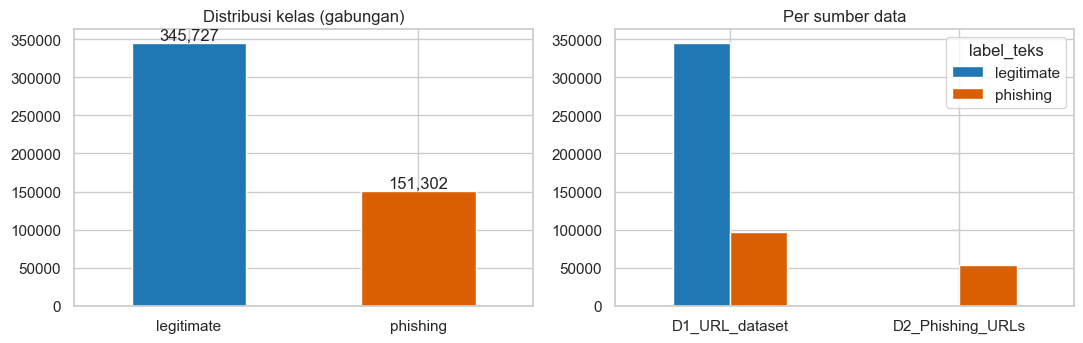

In [10]:
tab = pd.crosstab(df["sumber"], df["label_teks"], margins=True)
display(tab)
print("\nProporsi phishing keseluruhan: %.1f%%" % (100*df.label.mean()))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
df["label_teks"].value_counts().reindex(["legitimate","phishing"]).plot.bar(
    ax=ax[0], color=[WARNA["legitimate"], WARNA["phishing"]])
ax[0].set_title("Distribusi kelas (gabungan)"); ax[0].set_xlabel(""); ax[0].tick_params(axis="x", rotation=0)
for p in ax[0].patches: ax[0].annotate(f"{int(p.get_height()):,}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
pd.crosstab(df["sumber"], df["label_teks"]).plot.bar(ax=ax[1], color=[WARNA["legitimate"], WARNA["phishing"]])
ax[1].set_title("Per sumber data"); ax[1].set_xlabel(""); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(FIG/"01_distribusi_kelas.png", dpi=150); plt.show()

**Temuan:** data tidak seimbang secara ringan-sedang (phishing sekitar sepertiga). Ini masih wajar, jadi kita tangani dengan **pembobotan kelas pada data latih saja** (tidak perlu SMOTE, yang justru menciptakan URL sintetis yang tidak nyata).

## 5.  Temuan kunci: artefak skema (`https`) dan `www`
Cek ini penting karena menentukan apakah model belajar *phishing* sungguhan atau hanya *cara data dikumpulkan*.

,% memakai https,% diawali www.
label_teks,,
legitimate,100.0,99.8
phishing,6.2,7.9


Dataset 2 (phishing modern): 89.8% memakai https, 3.0% diawali www.


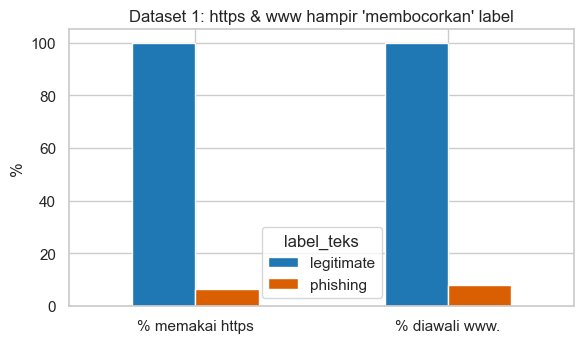

In [11]:
d1_only = df[df.sumber == "D1_URL_dataset"].copy()
d1_only["https"] = d1_only["url"].str.lower().str.startswith("https")
d1_only["www"]   = d1_only["url"].str.lower().str.contains(r"^[a-z]+://www\.")
art = d1_only.groupby("label_teks")[["https", "www"]].mean().mul(100).round(1)
art.columns = ["% memakai https", "% diawali www."]
display(art)

d2_only = df[df.sumber == "D2_Phishing_URLs"]
print("Dataset 2 (phishing modern): %.1f%% memakai https, %.1f%% diawali www." % (
    100*d2_only.url.str.lower().str.startswith('https').mean(),
    100*d2_only.url.str.lower().str.contains(r'^[a-z]+://www\.').mean()))

ax = art.T.plot.bar(figsize=(6, 3.6), color=[WARNA["legitimate"], WARNA["phishing"]])
ax.set_ylabel("%"); ax.set_title("Dataset 1: https & www hampir 'membocorkan' label"); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(FIG/"02_artefak_https_www.png", dpi=150); plt.show()

**Interpretasi dan keputusan**
- Di Dataset 1, URL legitimate **semuanya** memakai `https` dan hampir semuanya berawalan `www.`. Phishing di dataset yang sama jarang memakai keduanya.
- Itu **bukan sifat asli phishing**. Di dunia nyata banyak situs phishing sudah ber-https (sertifikat gratis), dan Dataset 2 membuktikannya.
- Model yang melihat `https`/`www` akan tampak sangat akurat di data uji, tetapi **gagal di lapangan** (situs phishing ber-https dianggap aman).

**Keputusan:** skema dan `www.` **dibuang** pada tahap normalisasi (fungsi `normalisasi_url`). Model hanya boleh belajar dari domain, path, dan query. Di Notebook 2 kita akan membuktikan dampak keputusan ini dengan eksperimen *ablation*.

### 5.1 Artefak pengumpulan data lainnya
Selain `https`/`www`, kita cari pola teknis yang hanya muncul pada satu kelas karena **cara data dikumpulkan**, bukan karena sifat phishing.

In [12]:
pola = {"HTML-escape '&amp;'": r"&amp;", "URL terpotong (akhiran ...)": r"\.\.\.$", "tahun 2010-2015 di URL": r"20(?:1[0-5])", "TLD .dev": r"\.dev(?:/|$)"}
tab_art = pd.DataFrame({k: df["url"].str.contains(v, regex=True).groupby([df["sumber"], df["label_teks"]]).mean().mul(100) for k, v in pola.items()}).round(2)
display(tab_art)

HTML-escape '&amp;'  URL terpotong (akhiran ...)  \
sumber           label_teks                                                     
D1_URL_dataset   legitimate                 0.02                         0.00   
                 phishing                   5.48                         2.56   
D2_Phishing_URLs phishing                   4.92                         0.01   

                             tahun 2010-2015 di URL  TLD .dev  
sumber           label_teks                                    
D1_URL_dataset   legitimate                    5.38       0.0  
                 phishing                      1.43       0.0  
D2_Phishing_URLs phishing                      0.10      13.4

**Interpretasi:**
- `&amp;` dan akhiran `...` muncul pada sekitar 5% dan 2,6% phishing, tetapi hampir tidak ada pada legitimate. Itu jejak *scraping* (HTML-escape, URL terpotong), bukan perilaku phishing. **Keputusan:** dinormalkan (`&amp;`→`&`, `...` dibuang) di `normalisasi_url`.
- Tahun 2010–2015 lebih sering di legitimate, dan `.dev` hanya ada di phishing Dataset 2. Ini mencerminkan **perbedaan era dan sumber** data. Tidak bisa dihapus begitu saja, jadi dicatat sebagai **keterbatasan** dan diuji lewat eksperimen lintas sumber di Notebook 2.

## 6. Ekstraksi fitur
Fitur dibuat dari URL ternormalisasi, dikelompokkan menjadi: panjang, karakter khusus, komposisi karakter, struktur host (IP, subdomain, TLD), path, kata kunci sensitif, peniruan merek, dan entropi. Lihat `url_features.py` untuk definisi tiap fitur.

In [13]:
import time
t0 = time.time()
X = buat_matriks_fitur(df["url"])          # ekstraksi dari URL mentah (normalisasi dilakukan di dalam)
df["domain"] = df["url"].map(domain_terdaftar)   # dipakai untuk membagi data berdasarkan grup di Notebook 2
print(f"Fitur: {X.shape[1]} kolom x {len(X):,} baris | waktu {time.time()-t0:.0f} dtk")
print("Jumlah domain unik:", df["domain"].nunique())
print("Nilai kosong pada fitur:", int(X.isna().sum().sum()))
display(X.describe().T.round(2).head(12))

Fitur: 40 kolom x 497,029 baris | waktu 27 dtk
Jumlah domain unik: 142367
Nilai kosong pada fitur: 0


,count,mean,std,min,25%,50%,75%,max
len_url,497029.0,49.77,39.54,4.0,28.0,41.0,60.0,1944.0
len_host,497029.0,17.16,8.96,0.0,12.0,16.0,20.0,236.0
len_path,497029.0,26.81,25.96,0.0,9.0,21.0,38.0,1897.0
len_query,497029.0,5.59,29.12,0.0,0.0,0.0,0.0,1930.0
len_domain,497029.0,9.62,4.61,0.0,6.0,9.0,12.0,121.0
n_titik,497029.0,1.85,1.16,0.0,1.0,2.0,2.0,32.0
n_hyphen,497029.0,1.21,2.48,0.0,0.0,0.0,1.0,53.0
n_underscore,497029.0,0.39,1.29,0.0,0.0,0.0,0.0,200.0
n_slash,497029.0,2.34,1.57,0.0,1.0,2.0,3.0,102.0
n_tanya,497029.0,0.15,0.45,0.0,0.0,0.0,0.0,166.0


## 7. EDA fitur: mana yang membedakan kelas?
Kita ukur selisih rata-rata antar kelas dalam satuan standar deviasi (**Cohen's d**), plus *mutual information*. Dua ukuran ini mengurutkan fitur tanpa melatih model.

,rata2_legit,rata2_phishing,cohen_d,mutual_info
n_titik_host,1.286,1.637,0.519,0.041
angka_di_host,0.079,1.585,0.516,0.062
len_host,15.624,20.660,0.501,0.047
n_kata_sensitif,0.008,0.200,0.492,0.042
n_titik,1.654,2.292,0.491,0.041
n_hyphen_host,0.061,0.294,0.448,0.031
ekstensi_php,0.045,0.172,0.417,0.019
entropi_host,3.309,3.474,0.402,0.100
n_subdomain,0.259,0.501,0.377,0.020
n_hyphen,1.462,0.648,-0.372,0.029


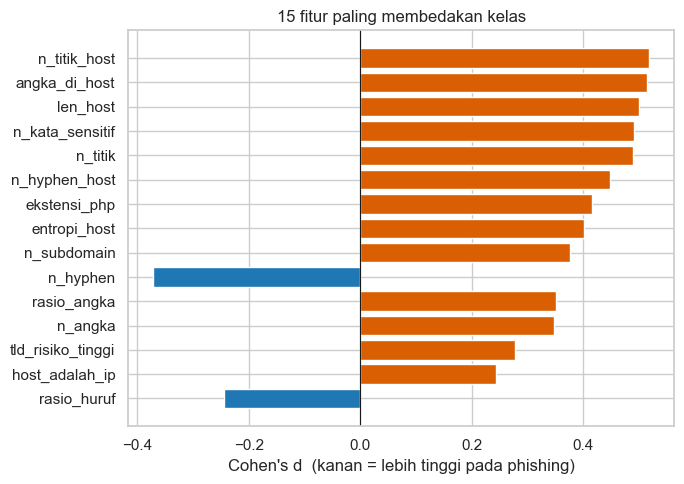

In [14]:
from sklearn.feature_selection import mutual_info_classif

y = df["label"].values
mu1, mu0 = X[y==1].mean(), X[y==0].mean()
sd = np.sqrt((X[y==1].var() + X[y==0].var())/2).replace(0, np.nan)
cohen = ((mu1 - mu0)/sd).fillna(0)

idx = np.random.RandomState(SEED).choice(len(X), 100_000, replace=False)   # sampel agar cepat
mi = pd.Series(mutual_info_classif(X.iloc[idx], y[idx], random_state=SEED), index=X.columns)

ringkas = pd.DataFrame({"rata2_legit": mu0, "rata2_phishing": mu1, "cohen_d": cohen, "mutual_info": mi})
ringkas = ringkas.reindex(cohen.abs().sort_values(ascending=False).index)
display(ringkas.round(3).head(15))

top = cohen.reindex(cohen.abs().sort_values().index).tail(15)
plt.figure(figsize=(7, 5))
plt.barh(top.index, top.values, color=[WARNA["phishing"] if v>0 else WARNA["legitimate"] for v in top.values])
plt.axvline(0, color="k", lw=.8); plt.xlabel("Cohen's d  (kanan = lebih tinggi pada phishing)")
plt.title("15 fitur paling membedakan kelas"); plt.tight_layout()
plt.savefig(FIG/"03_fitur_pembeda.png", dpi=150); plt.show()

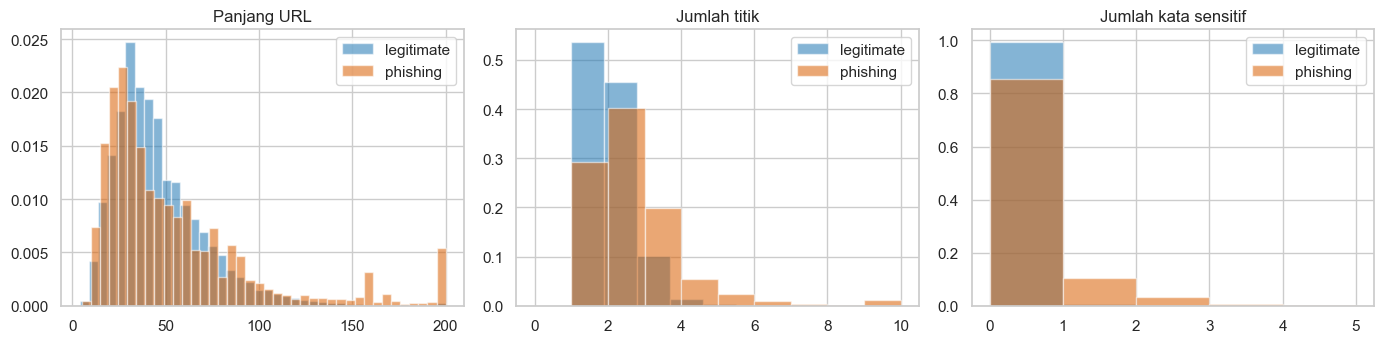

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, (kol, judul, batas) in zip(ax, [("len_url", "Panjang URL", 200), ("n_titik", "Jumlah titik", 10), ("n_kata_sensitif", "Jumlah kata sensitif", 5)]):
    for lab in ["legitimate", "phishing"]:
        s = X.loc[df.label_teks == lab, kol].clip(upper=batas)
        a.hist(s, bins=min(batas, 40), alpha=.55, density=True, label=lab, color=WARNA[lab])
    a.set_title(judul); a.legend()
plt.tight_layout(); plt.savefig(FIG/"04_distribusi_fitur.png", dpi=150); plt.show()

In [16]:
# Fitur biner: berapa % URL di tiap kelas yang punya sifat tersebut?
biner = ["host_adalah_ip", "n_at", "ada_http_di_path", "ekstensi_php", "ekstensi_html", "tld_risiko_tinggi", "merek_palsu", "pemendek_url", "ada_port"]
tabel = pd.DataFrame({k: (X[k] > 0).groupby(df["label_teks"]).mean()*100 for k in biner}).T.round(2)
tabel.columns = ["% legitimate", "% phishing"]
display(tabel)

,% legitimate,% phishing
host_adalah_ip,0.00,2.91
n_at,0.06,2.17
ada_http_di_path,0.01,1.93
ekstensi_php,4.50,17.18
ekstensi_html,21.31,12.34
tld_risiko_tinggi,0.34,4.63
merek_palsu,1.51,4.86
pemendek_url,0.00,1.36
ada_port,0.03,1.01


### 7.1 TLD teratas dan sebaran domain

In [17]:
tld = df["domain"].str.extract(r"\.([^.]+)$")[0]
top_tld = tld.value_counts().head(10).index
t = pd.crosstab(tld[tld.isin(top_tld)], df.loc[tld.isin(top_tld), "label_teks"], normalize="columns").mul(100).round(1)
display(t.sort_values("phishing", ascending=False))

dom_cnt = df.groupby("domain").size()
print("Domain dengan >50 URL:", (dom_cnt > 50).sum(), "| URL terbanyak dari satu domain:", dom_cnt.max(), "(%s)" % dom_cnt.idxmax())
print("Domain terbanyak per kelas:")
for lab in ["legitimate", "phishing"]:
    print(" ", lab, df[df.label_teks == lab]["domain"].value_counts().head(5).to_dict())

label_teks,legitimate,phishing
0,,
com,79.4,73.3
dev,0.0,7.0
net,3.4,5.3
org,10.4,3.9
ru,0.1,3.5
br,0.0,3.4
au,0.4,1.8
uk,1.4,1.3
ca,2.8,0.6


Domain dengan >50 URL: 711 | URL terbanyak dari satu domain: 12895 (wikipedia.org)
Domain terbanyak per kelas:
  legitimate {'wikipedia.org': 12895, 'youtube.com': 8627, 'facebook.com': 8275, 'blogspot.com': 7036, 'linkedin.com': 5016}
  phishing {'google.com': 5082, 'cf-ipfs.com': 4351, 'weeblysite.com': 3347, 'cloudflare-ipfs.com': 3209, 'pages.dev': 2479}


**Temuan penting dari sebaran domain:** banyak URL berasal dari domain yang sama (satu domain bisa punya ratusan URL). Jika dibagi acak, URL dari satu domain akan tersebar ke data latih **dan** uji. Model lalu "mengenali domain", bukan "mengenali phishing". Maka di Notebook 2 pembagian data dilakukan **per grup domain**.

Perhatikan juga: domain dari platform hosting gratis (mis. `pages.dev`, `firebaseapp.com`, `google.com` untuk Docs/Forms) hanya muncul sebagai phishing di Dataset 2. Ini akan kita bahas sebagai **keterbatasan**: model bisa menganggap seluruh platform tersebut mencurigakan.

### 7.2 Korelasi antar fitur (redundansi)

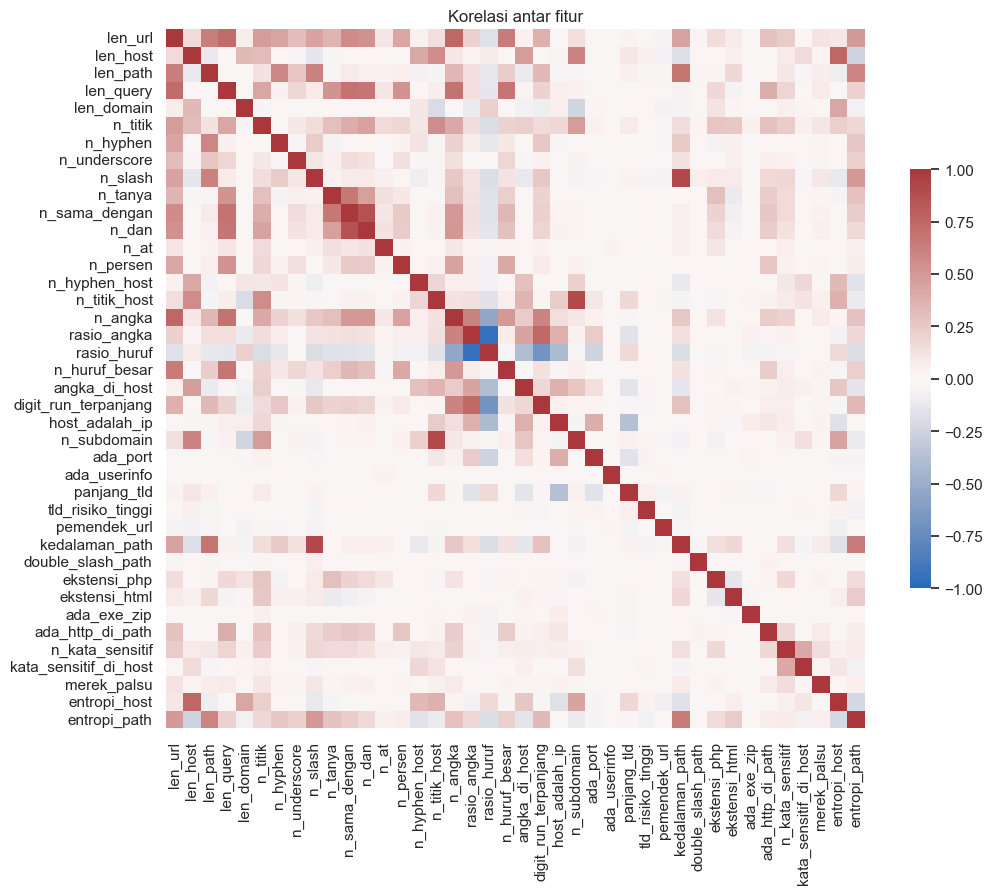

,,korelasi
n_slash,kedalaman_path,0.910
n_titik_host,n_subdomain,0.901
rasio_angka,rasio_huruf,-0.943


In [18]:
kor = X.iloc[idx].corr()
plt.figure(figsize=(11, 9))
sns.heatmap(kor, cmap="vlag", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"shrink": .6})
plt.title("Korelasi antar fitur"); plt.tight_layout(); plt.savefig(FIG/"05_korelasi.png", dpi=150); plt.show()

pasangan = kor.where(np.triu(np.ones(kor.shape), 1).astype(bool)).stack()
display(pasangan[pasangan.abs() > .9].sort_values(ascending=False).round(3).to_frame("korelasi"))

**Keputusan fitur:** beberapa fitur berkorelasi sangat tinggi (mis. `len_url` dengan `len_path`). Untuk **model pohon** (Random Forest, XGBoost) redundansi ini tidak merusak, jadi semua fitur dipertahankan. Untuk **Logistic Regression** redundansi hanya memengaruhi interpretasi koefisien, bukan akurasi. Jika kamu ingin latihan, coba hapus satu dari tiap pasangan berkorelasi >0,9 dan lihat dampaknya.

## 8. Kesesuaian data dengan input aplikasi

In [19]:
# Aplikasi menerima URL teks apa adanya dari pengguna (bisa dengan/tanpa skema & www).
# Uji: apakah fitur identik untuk variasi penulisan URL yang sama?
contoh = ["https://www.contoh.com/login", "http://contoh.com/login", "contoh.com/login", "HTTPS://WWW.CONTOH.COM/login"]
cek = buat_matriks_fitur(contoh)
print("Semua variasi menghasilkan fitur yang sama?  ",
      bool((cek.iloc[0].values == cek.iloc[1:].values).all(axis=1).all()))
display(cek.iloc[:, :6])

Semua variasi menghasilkan fitur yang sama?   True


,len_url,len_host,len_path,len_query,len_domain,n_titik
0,16.0,10.0,6.0,0.0,6.0,1.0
1,16.0,10.0,6.0,0.0,6.0,1.0
2,16.0,10.0,6.0,0.0,6.0,1.0
3,16.0,10.0,6.0,0.0,6.0,1.0


## 9. Menyimpan data olahan untuk Notebook 2

In [20]:
olah = pd.concat([df[["url", "url_norm", "domain", "sumber", "label_teks", "label"]].reset_index(drop=True),
                  X.reset_index(drop=True)], axis=1)
olah.to_parquet("data/data_olahan.parquet", index=False)
print("Tersimpan:", olah.shape, "->", "data/data_olahan.parquet")

Tersimpan: (497029, 46) -> data/data_olahan.parquet


## 10. Ringkasan temuan EDA → keputusan pengembangan model
| # | Temuan | Keputusan |
|---|---|---|
| 1 | Dataset hanya berisi URL mentah | Rancang 40 fitur leksikal sendiri + uji model teks (TF-IDF karakter) |
| 2 | Dataset 2 hanya phishing | Digabung dengan Dataset 1 (sesuai pilihan tim), kolom `sumber` disimpan untuk analisis per sumber |
| 3 | Duplikat dan label konflik setelah normalisasi | Dibuang sebelum pembagian data |
| 4 | `https`, `www.`, `&amp;`, dan `...` membocorkan label (artefak scraping) | Dinormalkan saat normalisasi, dibuktikan lewat ablation di Notebook 2 |
| 5 | Banyak URL berasal dari domain yang sama | Pembagian data per grup domain (anti-leakage) |
| 6 | Kelas tidak seimbang ringan-sedang | Pembobotan kelas hanya pada data latih |
| 7 | Era dan sumber berbeda: phishing modern (hosting gratis, `.dev`) hanya ada di Dataset 2, legitimate hanya dari Dataset 1 | Dicatat sebagai keterbatasan; diuji lewat eksperimen lintas sumber di Notebook 2 |
